In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from models.ALAD import ALAD
from matplotlib import pyplot as plt
from sklearn.metrics import auc, roc_curve


    
df = pd.read_csv('SimData.csv')
df = df.head(1000)
df = df[df['chi2'] <= 1000]

target_feature = "isghost"
# instantiate two more datasets one to contain the normal data
# and the other to hold the anomalous instances
normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

# also instantiate a dataframe to carry all the features
# and a second one to instead contain the target variable
features = df.drop([target_feature], axis=1)
label = df[target_feature]

# the stratify parameter here is set to be "isghost" meaning that the
# proportions of ghost and normal tracks in both train and test datasets
# will be kept the same...
x_train, x_test, y_train, y_test = train_test_split(
    features, label, test_size=0.2, stratify=label
)

# remember that at least for the autoencoders we're gonna use just the
# normal instances during the training phase so we have to filter those in x_train
train_index = y_train[y_train == 0].index
train_normal_data = x_train.loc[train_index]

train_normal_data = (train_normal_data - train_normal_data.mean()) / train_normal_data.std()
x_test = (x_test - train_normal_data.mean()) / train_normal_data.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

train_normal_data = scaler.fit_transform(train_normal_data)
x_test = scaler.fit_transform(x_test)

alad = ALAD(input_dim=train_normal_data.shape[1], latent_dim=3, learning_rate=0.003)
history = alad.train(train_normal_data, epochs=50, batch_size=128)


Epoch: 0,  Encoder Loss: 0.15892647206783295, Decoder Loss: 0.05501161515712738, Disc_xx Loss: 0.004379580728709698, Disc_xz Loss: 0.21393808722496033, Disc_zz Loss: 0.9365487694740295
Epoch: 1,  Encoder Loss: 0.0025326667819172144, Decoder Loss: 0.00013235209917183965, Disc_xx Loss: 1.304044031835254e-17, Disc_xz Loss: 0.0026650188956409693, Disc_zz Loss: 0.030729010701179504
Epoch: 2,  Encoder Loss: 3.21781262755394e-05, Decoder Loss: 7.475968732961746e-10, Disc_xx Loss: 0.0, Disc_xz Loss: 3.217887206119485e-05, Disc_zz Loss: 0.00017326086526736617
Epoch: 3,  Encoder Loss: 1.1629101663857e-06, Decoder Loss: 1.3236022283898922e-14, Disc_xx Loss: 0.0, Disc_xz Loss: 1.1629101663857e-06, Disc_zz Loss: 7.276095459474163e-08
Epoch: 4,  Encoder Loss: 1.1542616817905582e-07, Decoder Loss: 9.616994369188102e-17, Disc_xx Loss: 0.0, Disc_xz Loss: 1.1542616817905582e-07, Disc_zz Loss: 1.489599693593746e-10
Epoch: 5,  Encoder Loss: 2.4617476057642307e-08, Decoder Loss: 7.977091366800436e-20, Disc

In [20]:
def plot_ROC(y_test, predictions, name):

    # find the roc curve for the actual target values and the predictions
    fpr, tpr, _ = roc_curve(y_test, predictions)
    roc_auc = auc(fpr, tpr)

    #finding the Youden's J statistic, it's a metric that describes the power of classifier
    #where 0 is random guesser and 1 is a perfect classifier
    j_statistic = tpr - fpr
    print("the j_statistic is " + str(j_statistic[1]))

    #plotting the roc curve with the best trehsold against the random predictor
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + name)
    plt.legend(loc="lower right")
    plt.show()


the j_statistic is 0.1761252446183953


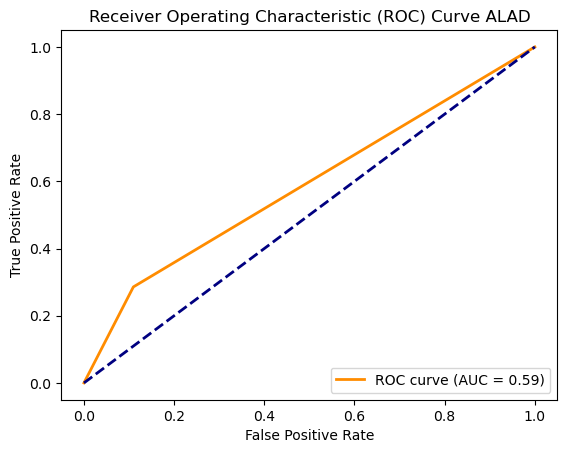

In [30]:
predictions = alad.predict(x_test)

threshold = np.percentile(predictions, 88.5)
predictions = np.where(predictions > threshold, 1, 0)

plot_ROC(y_test, predictions, "ALAD")


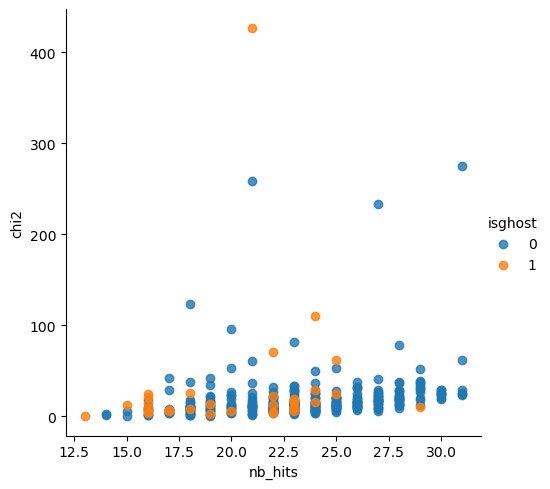

In [22]:
import seaborn as sns

sns.lmplot(x='nb_hits', y='chi2', hue='isghost', 
           data=df, 
           fit_reg=False)

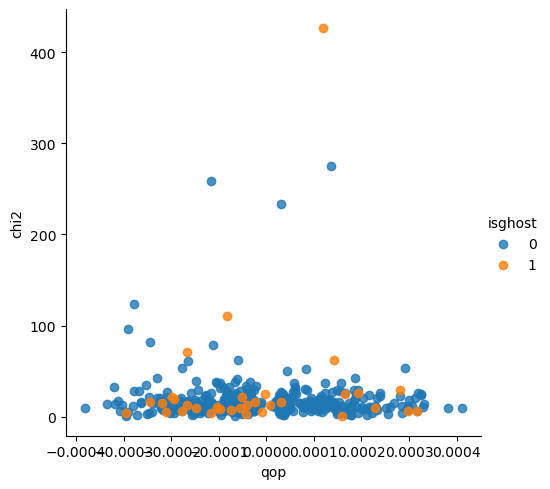

In [23]:
sns.lmplot(x='qop', y='chi2', hue='isghost', 
           data=df, 
           fit_reg=False)